# Global optimization and saddle points: the landscape of a Cooke triplet

Damped least squares (notebook [58 (lens optimization)](58_lens_optimization.ipynb))
goes downhill from the start to the nearest local minimum of the merit
function. Which minimum that is depends on the start, and lens design
problems have many. Even the simplest anastigmat, the Cooke triplet with
fixed glasses and thicknesses and only its curvatures free, has a dozen or
more local minima, most of them useless. The designer's skill, and the
role of experience and of the patent literature, is largely to start in
the right basin.

Since the early 2000s Florian Bociort and his group at TU Delft have
studied this landscape directly. Its minima form a **network**: each pair
of neighbouring minima is linked by a **saddle point** of Morse index 1 (a
point where the gradient vanishes and the Hessian has exactly one negative
eigenvalue, a mountain pass). And saddle points can be *constructed*: a
lens of zero thickness with equal curvatures changes nothing, and inserted
at the right place into a local minimum with N lenses it is a saddle point
of the landscape with N + 1 lenses. Rolling down on its two sides gives two
new minima, often good ones. This **saddle-point construction** is a
systematic way to add a lens to a design.

| section | content |
|---|---|
| 1 | the problem: a Cooke triplet with five free curvatures |
| 2 | a map of the local minima from 200 random starts |
| 3 | the pass between two minima: a nudged elastic band and the Hessian at the saddle point |
| 4 | the saddle-point construction: from doublets to triplets |
| 5 | global search: random starts, basin hopping and simulated annealing at equal cost |
| 6 | summary |

The tools are in `pyoptics.lens_landscape`, on top of the damped least
squares optimizer of `pyoptics.lens_optimization`.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import dual_annealing

from pyoptics import raytrace as rt
from pyoptics import lens_optimization as lo
from pyoptics import lens_landscape as ll
from pyoptics.materials import LAMBDA_F, LAMBDA_C, LAMBDA_d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
WL_F, WL_d, WL_C = LAMBDA_F*1e-6, LAMBDA_d*1e-6, LAMBDA_C*1e-6   # mm
t_start = time.time()

## 1. The problem

The triplet of notebook [58 (lens optimization)](58_lens_optimization.ipynb):
f = 50 mm, F/4.5, ±20° field, N-SK16 crowns outside, an N-F2 flint in the
middle, the stop 2 mm behind the flint. To keep the landscape low
dimensional, as in Bociort's studies, only the curvatures change: the
thicknesses (4, 1.5 and 4 mm) and air spaces (5, 2 and 3 mm) are fixed,
the last curvature is solved for the focal length, the image plane sits in
the paraxial focus and the entrance pupil is held at F/4.5. That leaves
**five variables** $c_1, c_2, c_3, c_4, c_5$, each limited to
$|c| \le 0.1$ mm⁻¹ ($|R| \ge 10$ mm). The merit function is the sum of
squares of the transverse ray errors at F, d and C on axis, at 0.7 and at
full field (tolerance 10 µm), as in notebook 58 (lens optimization).

Rays are aimed paraxially at the stop (no real ray aiming): this costs a
little accuracy at the edge of the field but makes an evaluation of the
merit function about 4 ms instead of up to a second for the strange
systems that random starts produce, and the thousands of local
optimizations below need that.

In [2]:
SK16, F2 = lo.GLASSES["N-SK16"], lo.GLASSES["N-F2"]
EPD, EFL, FIELD, CMAX = 50/4.5, 50.0, np.deg2rad(20.0), 0.1


def system(surfaces, stop):
    return rt.System(surfaces, stop, WL_d, field_angle=FIELD, entrance_pupil_radius=EPD/2,
                     ray_aiming=False)


def triplet(c):
    S = [rt.Surface(1/c[0], 4.0, material=SK16), rt.Surface(1/c[1], 5.0, n_after=1.0),
         rt.Surface(1/c[2], 1.5, material=F2), rt.Surface(1/c[3], 2.0, n_after=1.0),
         rt.Surface(np.inf, 3.0, semi_diameter=4.0),
         rt.Surface(1/c[4], 4.0, material=SK16), rt.Surface(-25.0, 40.0, n_after=1.0)]
    return system(S, 4)


def solves(efl_surface):
    return [lo.solve_curvature_for_efl(efl_surface, EFL), lo.solve_entrance_pupil(EPD/2),
            lo.solve_paraxial_focus()]


operands = [lo.polychromatic_ray_errors([WL_F, WL_d, WL_C], fields=(0.0, 0.7, 1.0),
                                        tolerance=0.01)]


def optimizer(s, surfaces, efl_surface):
    return lo.DampedLeastSquares(s, [lo.Curvature(i, (-CMAX, CMAX)) for i in surfaces], operands,
                                 solves=solves(efl_surface))


opt = optimizer(triplet([0.04, -0.005, -0.04, 0.05, 0.02]), (0, 1, 2, 3, 5), 6)
t0 = time.time()
for _ in range(20):
    opt.merit()
print(f"one merit function evaluation: {(time.time() - t0)/20*1e3:.1f} ms, "
      f"{len(opt.residuals())} residuals")

one merit function evaluation: 12.1 ms, 324 residuals


## 2. A map of the local minima

200 starting points, uniform in the box $|c_i| \le 0.1$ mm⁻¹ (only
points whose rays all trace are kept; about one in five of the box does),
each optimized with damped least squares until it stops. The end points
are clustered: two runs found the same minimum if no curvature differs by
more than 5 % of the curvature scale (1/60 mm⁻¹) and the merit functions
agree to 0.1 %. Runs that end with a curvature at the limit of the box
sit in a valley along the boundary rather than in a true minimum; they
are counted separately.

In [3]:
t0 = time.time()
starts = ll.random_starts(opt, 200, rng=1)
runs = ll.multistart(opt, starts, max_iterations=150)
minima_all = ll.cluster_minima(runs, opt)
minima = [m for m in minima_all if not m.at_bound]
bound_runs = sum(m.count for m in minima_all if m.at_bound)
failed = sum(not np.isfinite(r.merit) for r in runs)
evals_per_run = np.mean([r.evaluations for r in runs])
print(f"{len(runs)} runs in {time.time() - t0:.0f} s, {evals_per_run:.0f} merit evaluations per run")
print(f"{len(minima)} distinct interior minima, {bound_runs} runs end at a bound, {failed} failed\n")
print(" #   merit    runs   c1       c2       c3       c4       c5 [1/mm]")
for k, m in enumerate(minima):
    print(f"{k:2d} {m.merit:9.0f} {m.count:5d}  " + " ".join(f"{c:+.4f}" for c in m.x))

200 runs in 290 s, 332 merit evaluations per run
11 distinct interior minima, 91 runs end at a bound, 0 failed

 #   merit    runs   c1       c2       c3       c4       c5 [1/mm]
 0       648    42  +0.0474 -0.0036 -0.0390 +0.0535 +0.0143
 1      6104     9  -0.0461 -0.0260 +0.0373 +0.0503 +0.0218
 2      9959     5  -0.0633 -0.0622 -0.0800 -0.0684 +0.0023
 3     22132    18  -0.0518 -0.0344 -0.0149 -0.0317 +0.0075
 4     26813     6  -0.0503 -0.0435 +0.0296 -0.0053 +0.0750
 5     27527     1  -0.0761 -0.0673 +0.0046 -0.0322 -0.0751
 6     29024     6  -0.0645 -0.0498 +0.0013 -0.0445 -0.0780
 7     29757     4  -0.0556 +0.0115 -0.0132 -0.0485 +0.0152
 8     32129     5  +0.0372 +0.0019 -0.0572 -0.0545 +0.0760
 9     49806    12  +0.0366 +0.0196 +0.0582 +0.0376 +0.0715
10   1049837     1  +0.0149 -0.0146 -0.0900 -0.0880 +0.0760


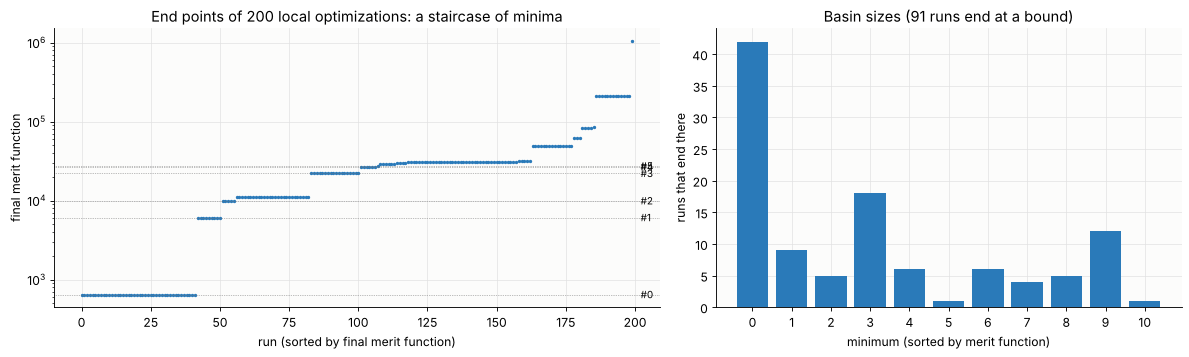

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
merits = np.array([r.merit for r in runs])
order = np.argsort(merits)
ax.semilogy(np.arange(len(runs)), merits[order], ".", color=BLUE, ms=4)
for k, m in enumerate(minima[:6]):
    ax.axhline(m.merit, color=GREY, lw=0.6, ls=":")
    ax.text(len(runs)*1.01, m.merit, f"#{k}", va="center", fontsize=9)
ax.set_xlabel("run (sorted by final merit function)")
ax.set_ylabel("final merit function")
ax.set_title("End points of 200 local optimizations: a staircase of minima")
ax = axes[1]
ax.bar(np.arange(len(minima)), [m.count for m in minima], color=BLUE)
ax.set_xticks(np.arange(len(minima)))
ax.set_xlabel("minimum (sorted by merit function)")
ax.set_ylabel("runs that end there")
ax.set_title(f"Basin sizes ({bound_runs} runs end at a bound)")
fig.tight_layout()

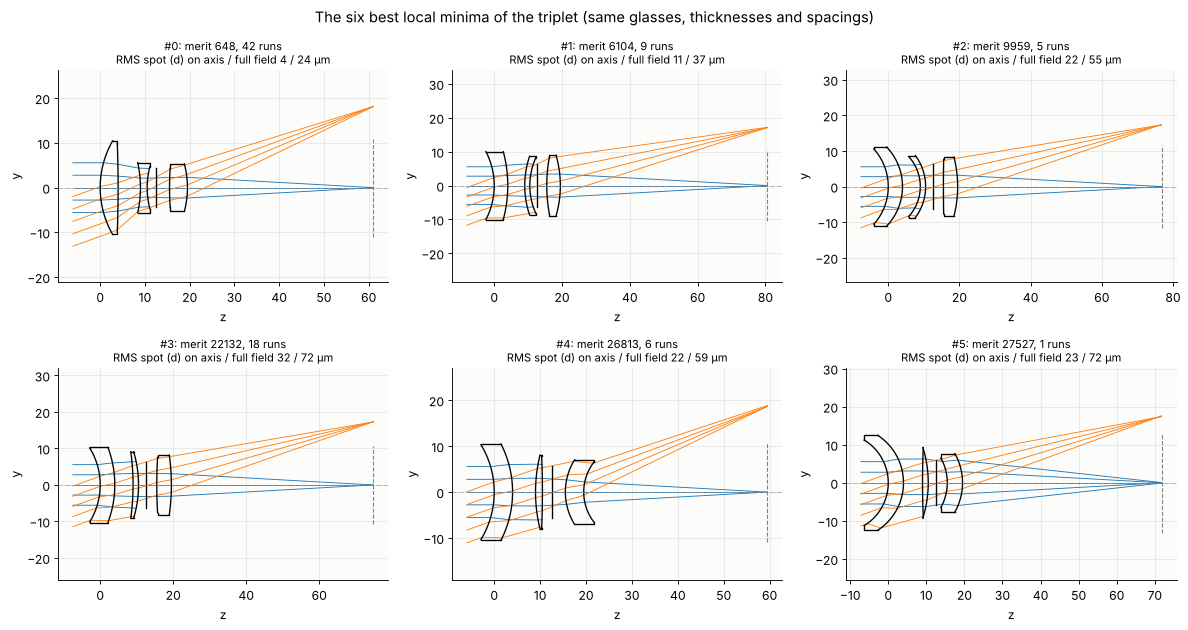

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for k, ax in enumerate(axes.flat):
    if k >= len(minima):
        ax.axis("off")
        continue
    s = opt.system_at(minima[k].x)
    s.draw(ax, fields=[0.0, s.max_field], n_rays=5)
    ax.set_aspect("equal")
    ax.set_title(f"#{k}: merit {minima[k].merit:.0f}, {minima[k].count} runs\n"
                 f"RMS spot (d) on axis / full field "
                 f"{s.spot_diagram(0.0, N=15).rms*1e3:.0f} / "
                 f"{s.spot_diagram(FIELD, N=15).rms*1e3:.0f} µm", fontsize=10)
fig.suptitle("The six best local minima of the triplet (same glasses, thicknesses and spacings)")
fig.tight_layout()

The best minimum, #0, is the classic Cooke form: a nearly plano-convex
front crown, a biconcave flint and an equiconvex rear crown, the design of
notebook 58 (lens optimization) (there with free air spaces and real ray
aiming). It is also the minimum with the largest basin. The others are
caricatures of a triplet: front lenses bent the wrong way, the negative
power moved to the front, menisci that trade field correction for
spherical aberration. A merit function one or two orders of magnitude
higher means spots two to eight times larger. Here the global minimum is
easy to find, since about one random start in five ends there; in larger
systems the fraction falls quickly (Bociort and co-workers found that
basins of attraction in lens design can even be fractal, so that a tiny
change of the start, or of the damping, sends the optimizer to another
minimum).

## 3. The pass between two minima

Two neighbouring minima are linked by a path that goes over a pass, a
saddle point of Morse index 1: along the path the merit function has a
maximum there, across the path a minimum. A **nudged elastic band**
(Henkelman, Uberuaga and Jónsson, 2000) finds it: a chain of images
between the two minima relaxes under the part of the gradient across the
chain, springs keep the images apart, and the highest image climbs up
along the chain until it sits in the saddle point. The landscape is so
anisotropic that a band relaxed by steepest descent converges slowly, so
after 100 iterations its highest image is handed to eigenvector following
(`refine_stationary(index=1)`, Baker's partitioned rational function
steps: uphill along the lowest eigenvector of the Hessian, downhill along
all others), which converges onto the saddle point. The eigenvalues of
the Hessian there show its index.

We take minima #3 and #4: both have a negative front meniscus and a
positive flint (the roles of the Cooke form turned around), and they
differ mainly in the rear crown.

In [6]:
t0 = time.time()
A, B = 3, 4
a, b = minima[A], minima[B]
path = ll.minimum_energy_path(opt, a.x, b.x, images=13, iterations=100, step=0.05)
t1 = time.time()
x_s, st_s = ll.refine_stationary(opt, path.x[path.saddle], iterations=40, index=1, max_step=0.1)
st_a = ll.stationarity(opt, a.x)
print(f"band: {t1 - t0:.0f} s (highest image: merit {path.merit[path.saddle]:.0f}), "
      f"eigenvector following: {time.time() - t1:.0f} s")
print(f"saddle point: merit {ll.merit_at(opt, x_s):.0f} (minima {a.merit:.0f} and {b.merit:.0f}), "
      f"Morse index {st_s.morse_index}, largest gradient component {np.max(np.abs(st_s.gradient)):.1g}")
print(f"Hessian eigenvalues at minimum #{A}:", np.array2string(st_a.eigenvalues, precision=3))
print("Hessian eigenvalues at the saddle:", np.array2string(st_s.eigenvalues, precision=3))
print("curvatures at the saddle:", np.round(x_s, 4))
down, _ = ll.descend_from_saddle(opt, x_s, step=0.1, stationary=st_s)
print("downhill from the saddle point on both sides:",
      ", ".join(f"merit {r.merit:.0f}" for r in down))
s_sad = opt.system_at(x_s)
n_r = s_sad.n[6]
c5, c6 = s_sad.surfaces[5].c, s_sad.surfaces[6].c
P_rear = (n_r - 1)*(c5 - c6) + (n_r - 1)**2*4.0*c5*c6/n_r
print(f"rear crown at the saddle: c = {c5:+.4f}, {c6:+.4f} 1/mm, focal length {1/P_rear:.0f} mm")
for k in (A, B):
    sk = opt.system_at(minima[k].x)
    ck5, ck6 = sk.surfaces[5].c, sk.surfaces[6].c
    Pk = (n_r - 1)*(ck5 - ck6) + (n_r - 1)**2*4.0*ck5*ck6/n_r
    print(f"rear crown of #{k}:        c = {ck5:+.4f}, {ck6:+.4f} 1/mm, focal length {1/Pk:.0f} mm")

band: 29 s (highest image: merit 84218), eigenvector following: 2 s
saddle point: merit 76453 (minima 22132 and 26813), Morse index 1, largest gradient component 2e-06
Hessian eigenvalues at minimum #3: [   5638.95     9952.051   50034.102   99137.917 3528169.753]
Hessian eigenvalues at the saddle: [  -40610.894    27778.189    51787.335   241360.901 22768437.256]
curvatures at the saddle: [-0.0618 -0.0464  0.0044 -0.0321  0.0372]


downhill from the saddle point on both sides: merit 26814, merit 22132
rear crown at the saddle: c = +0.0372, +0.0395 1/mm, focal length 87215 mm
rear crown of #3:        c = +0.0075, -0.0171 1/mm, focal length 66 mm
rear crown of #4:        c = +0.0750, +0.0932 1/mm, focal length -217 mm


In [7]:
# a slice of the landscape through the two minima and the saddle point
scale = opt._scale
u = (b.x - a.x)/scale
w = (x_s - a.x)/scale
e1 = u/np.linalg.norm(u)
w_perp = w - (w @ e1)*e1
e2 = w_perp/np.linalg.norm(w_perp)
L = np.linalg.norm(u)
s1 = np.linspace(-0.25*L, 1.25*L, 41)
s2 = np.linspace(-0.9*L, 0.9*L, 37) + (w @ e2)/2
t0 = time.time()
M = np.array([[ll.merit_at(opt, a.x + (p*e1 + q*e2)*scale) for p in s1] for q in s2])
print(f"slice: {M.size} evaluations in {time.time() - t0:.0f} s")

slice: 1517 evaluations in 7 s


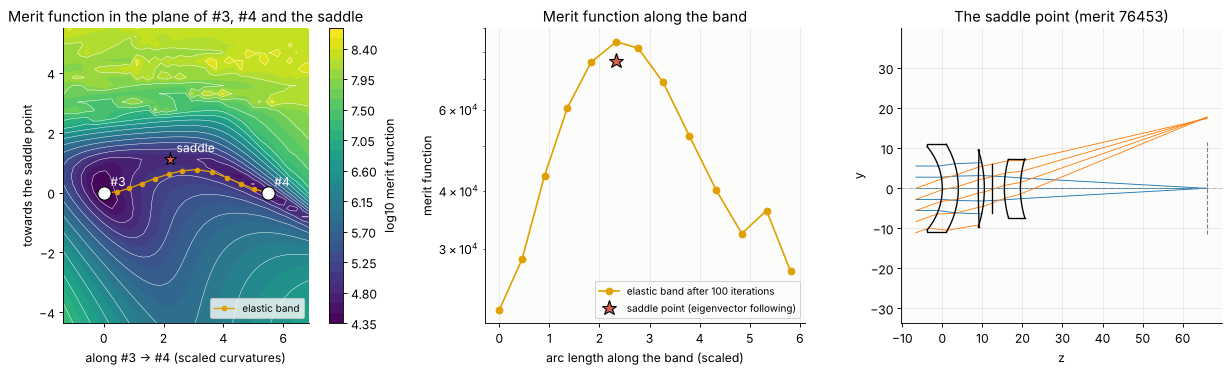

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.25, 1, 1]})
ax = axes[0]
lev = np.log10(np.where(np.isfinite(M), M, np.nan))
cs = ax.contourf(s1, s2, lev, levels=30, cmap="viridis")
ax.contour(s1, s2, lev, levels=15, colors="w", linewidths=0.4)
fig.colorbar(cs, ax=ax, label="log10 merit function")
P = (path.x - a.x)/scale
ax.plot(P @ e1, P @ e2, "o-", color=ORANGE, ms=4, lw=1.2, label="elastic band")
for x, name in [(a.x, f"#{A}"), (b.x, f"#{B}"), (x_s, "saddle")]:
    z = (x - a.x)/scale
    ax.plot(z @ e1, z @ e2, "*" if name == "saddle" else "o", color=RED if name == "saddle" else "w",
            ms=12, mec="k")
    ax.annotate(name, (z @ e1, z @ e2), xytext=(6, 6), textcoords="offset points", color="w")
ax.set_xlabel(f"along #{A} -> #{B} (scaled curvatures)")
ax.set_ylabel("towards the saddle point")
ax.set_title(f"Merit function in the plane of #{A}, #{B} and the saddle")
ax.set_aspect("equal")
ax.legend(fontsize=9, loc="lower right")
ax.grid(False)
ax = axes[1]
arc = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(P, axis=0), axis=1))])
ax.semilogy(arc, path.merit, "o-", color=ORANGE, label="elastic band after 100 iterations")
zs = (x_s - a.x)/scale
k_near = int(np.argmin(np.linalg.norm(P - zs, axis=1)))
ax.semilogy(arc[k_near], ll.merit_at(opt, x_s), "*", color=RED, ms=14, mec="k",
            label="saddle point (eigenvector following)")
ax.set_xlabel("arc length along the band (scaled)")
ax.set_ylabel("merit function")
ax.set_title("Merit function along the band")
ax.legend(fontsize=9)
ax = axes[2]
s = opt.system_at(x_s)
s.draw(ax, fields=[0.0, s.max_field], n_rays=5)
ax.set_aspect("equal")
ax.set_title(f"The saddle point (merit {ll.merit_at(opt, x_s):.0f})")
fig.tight_layout()

The band starts as a straight line in the five curvatures and bends
towards the pass; from its highest image, eigenvector following converges
to a stationary point with exactly one negative eigenvalue of the Hessian,
and downhill on its two sides lie #3 and #4 again: it is the saddle point
between them. Note the rear crown there: it is almost without power. The
saddle point between two triplets is a doublet with a nearly null lens
behind the stop, which is just what the construction of the next section
builds on purpose. The merit function at the pass is what a local
optimizer would have to climb to get from one minimum to the other: damped
least squares never does, so once a design is in a basin, it stays there.
The slice also shows how narrow the valleys are: the eigenvalues of the
Hessian at the minimum span several orders of magnitude (the merit function
is very sensitive to some combinations of curvatures, such as the power of
a lens, and hardly to others, such as its bending).

## 4. The saddle-point construction: from doublets to triplets

Take a local minimum of a system and insert, somewhere in air, a lens of
**zero thickness** whose two surfaces have the same curvature $c$. It
changes nothing: a ray enters and leaves it at the same point through
parallel surfaces. The new system has two more variables, the curvatures
of the new surfaces, and the merit function as a function of all of them
has:

- zero gradient along the old variables (the old system is a minimum),
- zero gradient along the *bending* of the null lens ($c_a = c_b$ together:
  the lens stays a null lens),
- a derivative along its *power* ($c_b - c_a$) that depends on $c$; to third
  order it is quadratic in $c$, so it vanishes at two curvatures, or none.

At such a curvature the system is a stationary point of the bigger
landscape, and Bociort and van Turnhout showed that it is a saddle point
of Morse index 1 (with a zero eigenvalue along the bending, which the
thickness of a real lens lifts). Following the negative eigenvector
downhill on both sides gives two minima of the landscape with one lens
more. (Inserted in contact with a surface, with that surface's curvature
and the glass in front of it, the null lens gives a saddle point directly,
`insert_null_lens()` with the defaults.)

We start from doublets: the triplet without its rear crown (front crown,
flint, stop; three curvatures free, the rear curvature of the flint solved
for the focal length). Its map has a few minima. Into each, a null lens of
N-SK16 goes 3 mm behind the stop, where the triplet has its rear crown.
Recipe, for each curvature at which the system is stationary:

1. the Hessian at the saddle point and its most negative eigenvector;
2. damped least squares from both sides, 0.1 (scaled) along that
   eigenvector, with the new lens still of zero thickness;
3. the two thin minima made thick, 1, 2, 3, 4 mm, re-optimized at each step
   (a minimum moves continuously with the thickness).

The triplets have the same glasses, thicknesses and spacings as in the map
of section 2, so each result can be looked up there.

In [9]:
def doublet(c):
    S = [rt.Surface(1/c[0], 4.0, material=SK16), rt.Surface(1/c[1], 5.0, n_after=1.0),
         rt.Surface(1/c[2], 1.5, material=F2), rt.Surface(-30.0, 2.0, n_after=1.0),
         rt.Surface(np.inf, 40.0, semi_diameter=4.0)]
    return system(S, 4)


def front_doublet(c):
    # flint, stop and rear crown, with an empty plane 9 mm in front of the flint
    S = [rt.Surface(np.inf, 9.0), rt.Surface(1/c[0], 1.5, material=F2),
         rt.Surface(1/c[1], 2.0, n_after=1.0), rt.Surface(np.inf, 3.0, semi_diameter=4.0),
         rt.Surface(1/c[2], 4.0, material=SK16), rt.Surface(-30.0, 40.0, n_after=1.0)]
    return system(S, 3)


# how to build each kind of triplet from a doublet
CASES = {
    "rear crown behind the stop": dict(
        make=doublet, start=[0.03, -0.01, -0.02], variables=(0, 1, 2), efl=3,
        insert=4, distance=3.0,          # null lens 3 mm behind surface 4 (the stop)
        lens=5, gap=None,                # the new lens is surfaces 5-6; it takes no air space
        triplet_variables=(0, 1, 2, 5, 6), triplet_efl=3,
        map_surfaces=(0, 1, 2, 3, 5)),   # the surfaces that are c1 ... c5 of the map
    "front crown before the flint": dict(
        make=front_doublet, start=[-0.03, 0.03, -0.02], variables=(1, 2, 4), efl=5,
        insert=0, distance=0.0, lens=1, gap=9.0,   # the lens shares the 9 mm with the air space
        triplet_variables=(1, 2, 3, 4, 6), triplet_efl=7,
        map_surfaces=(1, 2, 3, 4, 6)),
}


def doublet_minima(case, n=40):
    o = optimizer(case["make"](case["start"]), case["variables"], case["efl"])
    runs = ll.multistart(o, ll.random_starts(o, n, rng=5), max_iterations=150)
    return o, [m for m in ll.cluster_minima(runs, o) if not m.at_bound]


def with_lens(s, case, t):
    s = s.copy()
    s.surfaces[case["lens"]].thickness = t
    if case["gap"] is not None:
        s.surfaces[case["lens"] + 1].thickness = case["gap"] - t
    return s


def match(c, merit):
    # name of the minimum of the map with these curvatures c1 ... c5
    for m in minima_all:
        if np.max(np.abs(c - m.x)/opt._scale) < 0.05 and abs(merit - m.merit) < 2e-3*m.merit:
            return "at bound" if m.at_bound else f"#{[mm is m for mm in minima].index(True)}"
    return "new"


def construct(case, d_sys, thickness=4.0, glass=SK16):
    # all saddle points of one doublet minimum and the triplets on both sides
    tv, te = case["triplet_variables"], case["triplet_efl"]
    null, ij = ll.insert_null_lens(d_sys, case["insert"], glass, 0.0, distance=case["distance"])
    out = []
    for c in ll.null_lens_curvatures(optimizer(null, tv, te), ij, np.linspace(-0.1, 0.1, 21)):
        s0, _ = ll.insert_null_lens(d_sys, case["insert"], glass, c, distance=case["distance"])
        o0 = optimizer(s0, tv, te)
        runs, st0 = ll.descend_from_saddle(o0, o0.x, step=0.1, max_iterations=200)
        ends = []
        for r in runs:
            x, track = r.x, [r.merit]
            for t in np.linspace(0, thickness, 5)[1:]:
                o = optimizer(with_lens(s0, case, t), tv, te)
                rr = ll.local_search(o, x, max_iterations=200)
                x = rr.x
                track.append(rr.merit)
            s = o.system_at(x)
            cm = np.array([s.surfaces[k].c for k in case["map_surfaces"]])
            ends.append(dict(system=s, merit=rr.merit, track=track, name=match(cm, rr.merit)))
        out.append(dict(c=c, system=s0, saddle_merit=o0.merit(), st=st0, ends=ends))
    return out


t0 = time.time()
rear = CASES["rear crown behind the stop"]
dopt, doublets = doublet_minima(rear)
constructions = [construct(rear, dopt.system_at(m.x)) for m in doublets]
print(f"{time.time() - t0:.0f} s\n")
print("doublet      merit   c of null lens  Morse index  eigenvalues of the Hessian at the saddle")
for k, (m, cons) in enumerate(zip(doublets, constructions)):
    for e in cons:
        print(f"D{k} {m.merit:12.0f}   {e['c']:+.4f}        {e['st'].morse_index}        "
              + np.array2string(e["st"].eigenvalues, precision=2, max_line_width=200))
        for side, end in enumerate(e["ends"]):
            print(f"{'':20s} side {side + 1}: thin {end['track'][0]:8.0f} -> 4 mm {end['merit']:8.0f}"
                  f"   map minimum {end['name']}")

51 s

doublet      merit   c of null lens  Morse index  eigenvalues of the Hessian at the saddle
D0        76645   -0.0941        1        [-1.46e+05  2.07e+04  1.08e+05  3.54e+05  1.03e+08]
                     side 1: thin    68484 -> 4 mm    27527   map minimum #5
                     side 2: thin    39841 -> 4 mm    29024   map minimum #6
D0        76645   -0.0406        1        [ -21667.69   45978.73  103793.6   136443.79 6074909.23]
                     side 1: thin    39841 -> 4 mm    29024   map minimum #6
                     side 2: thin    24405 -> 4 mm    22132   map minimum #3
D0        76645   +0.0402        1        [-1.14e+04  3.57e+04  4.66e+04  4.88e+05  1.27e+07]
                     side 1: thin    24405 -> 4 mm    22132   map minimum #3
                     side 2: thin    25796 -> 4 mm    26813   map minimum #4
D1       118342   -0.0626        1        [-1.08e+04  2.20e+04  6.57e+04  3.01e+05  2.25e+08]
                     side 1: thin    90249 -> 4 mm    83178 

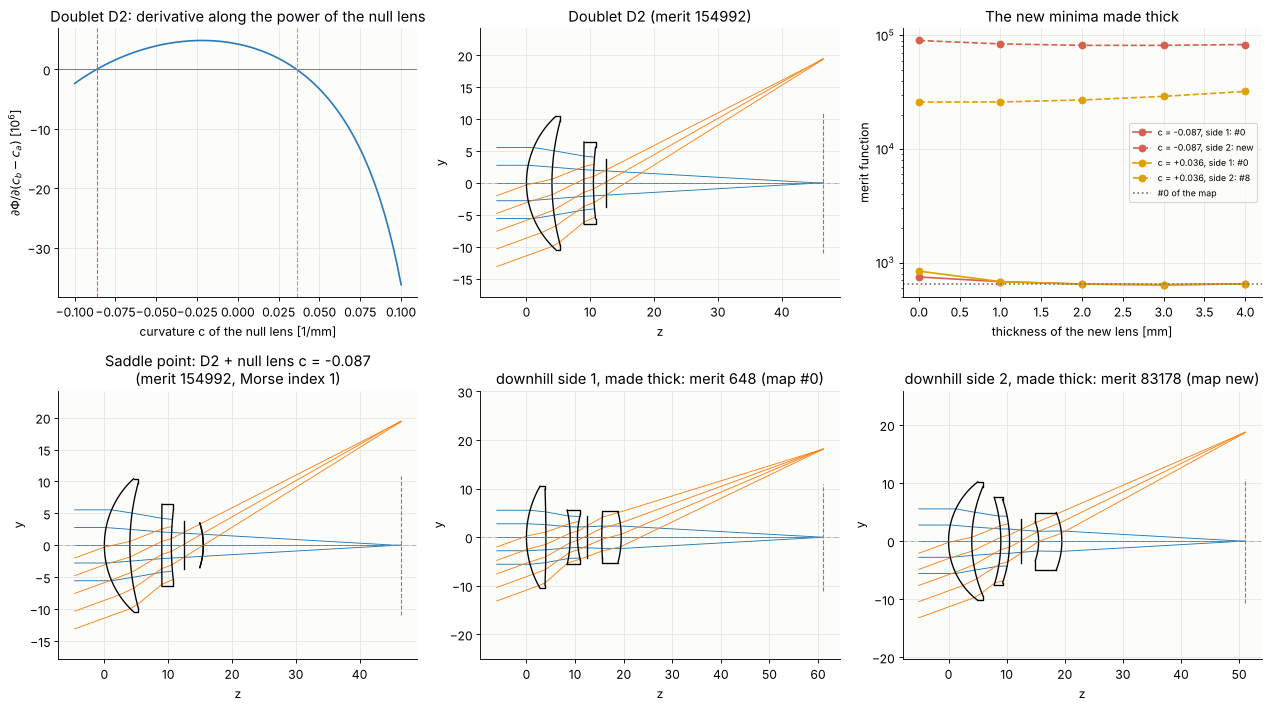

In [10]:
# the construction that leads to the best triplet, in detail
k_best, e_best = min(((k, e) for k, cons in enumerate(constructions) for e in cons),
                     key=lambda t: min(end["merit"] for end in t[1]["ends"]))
D = doublets[k_best]
d_sys = dopt.system_at(D.x)
null, ij = ll.insert_null_lens(d_sys, 4, SK16, 0.0, distance=3.0)
cc = np.linspace(-0.1, 0.1, 81)
g = ll.null_lens_gradient(optimizer(null, (0, 1, 2, 5, 6), 3), ij, cc)

fig = plt.figure(figsize=(16, 9))
ax = fig.add_subplot(2, 3, 1)
ax.plot(cc, g/1e6, color=BLUE)
ax.axhline(0, color=GREY, lw=0.8)
for e in constructions[k_best]:
    ax.axvline(e["c"], color=RED if e is e_best else ORANGE, ls="--", lw=1)
ax.set_xlabel("curvature c of the null lens [1/mm]")
ax.set_ylabel(r"$\partial\Phi/\partial(c_b - c_a)$ [10$^6$]")
ax.set_title(f"Doublet D{k_best}: derivative along the power of the null lens")
ax = fig.add_subplot(2, 3, 2)
d_sys.draw(ax, fields=[0.0, d_sys.max_field], n_rays=5)
ax.set_aspect("equal")
ax.set_title(f"Doublet D{k_best} (merit {D.merit:.0f})")
ax = fig.add_subplot(2, 3, 3)
for e in constructions[k_best]:
    color = RED if e is e_best else ORANGE
    for side, end in enumerate(e["ends"]):
        ax.semilogy([0, 1, 2, 3, 4], end["track"], "o", color=color, ls=["-", "--"][side],
                    label=f"c = {e['c']:+.3f}, side {side + 1}: {end['name']}")
ax.axhline(minima[0].merit, color=GREY, ls=":", label="#0 of the map")
ax.set_xlabel("thickness of the new lens [mm]")
ax.set_ylabel("merit function")
ax.set_title("The new minima made thick")
ax.legend(fontsize=8)
ax = fig.add_subplot(2, 3, 4)
e_best["system"].draw(ax, fields=[0.0, d_sys.max_field], n_rays=5)
ax.set_aspect("equal")
ax.set_title(f"Saddle point: D{k_best} + null lens c = {e_best['c']:+.3f}\n"
             f"(merit {e_best['saddle_merit']:.0f}, Morse index {e_best['st'].morse_index})")
for side, end in enumerate(e_best["ends"]):
    ax = fig.add_subplot(2, 3, 5 + side)
    end["system"].draw(ax, fields=[0.0, d_sys.max_field], n_rays=5)
    ax.set_aspect("equal")
    ax.set_title(f"downhill side {side + 1}, made thick: merit {end['merit']:.0f} "
                 f"(map {end['name']})")
fig.tight_layout()

The derivative along the power of the null lens has two zeros in the
range of curvatures, as the third order theory predicts (with real rays
there can be more, as for D0 in the table). At each zero the
Hessian has one clearly negative eigenvalue; the eigenvalue of the
bending of the null lens, which is exactly zero, comes out small but not
zero, because the finite differences are limited by the largest
eigenvalue, the power of the new lens. Downhill on the two sides lie two
triplets with a lens of zero thickness, and they stay minima while the
lens grows to 4 mm. Nearly all are minima of the map of section 2 (the
two marked "new" end with a curvature at the limit of 0.1 mm⁻¹, in valleys
along the boundary). Here the construction does not invent designs, it
*finds* minima of the bigger landscape systematically, starting from the
smaller one, without random starts, and among them the Cooke form: both
saddle points of doublet D2 lead to it.

The same with the front crown inserted in front of a flint + rear crown
doublet: the null lens goes into an empty plane 9 mm in front of the
flint, and the new lens takes its 4 mm from that air space. Each saddle
point links two triplet minima: these are the edges of Bociort's network.

In [11]:
t0 = time.time()
front = CASES["front crown before the flint"]
fopt, fdoublets = doublet_minima(front)
fconstructions = [construct(front, fopt.system_at(m.x)) for m in fdoublets]
print(f"{time.time() - t0:.0f} s\n")
for k, (m, cons) in enumerate(zip(fdoublets, fconstructions)):
    for e in cons:
        print(f"F{k} {m.merit:10.0f}  c = {e['c']:+.4f}  Morse index {e['st'].morse_index}  ->  "
              + ",  ".join(f"{end['merit']:.0f} ({end['name']})" for end in e["ends"]))

118 s

F0      45726  c = -0.0761  Morse index 1  ->  9959 (#2),  9959 (#2)
F0      45726  c = -0.0460  Morse index 1  ->  9959 (#2),  9959 (#2)
F0      45726  c = -0.0211  Morse index 1  ->  11141 (at bound),  9959 (#2)
F0      45726  c = +0.0520  Morse index 1  ->  11141 (at bound),  11141 (at bound)
F1      79131  c = -0.0039  Morse index 1  ->  49806 (#9),  26813 (#4)
F1      79131  c = +0.0529  Morse index 1  ->  49611 (at bound),  49806 (#9)
F2     276706  c = +0.0064  Morse index 1  ->  648 (#0),  29024 (#6)
F2     276706  c = +0.0903  Morse index 1  ->  211660 (at bound),  83182 (new)


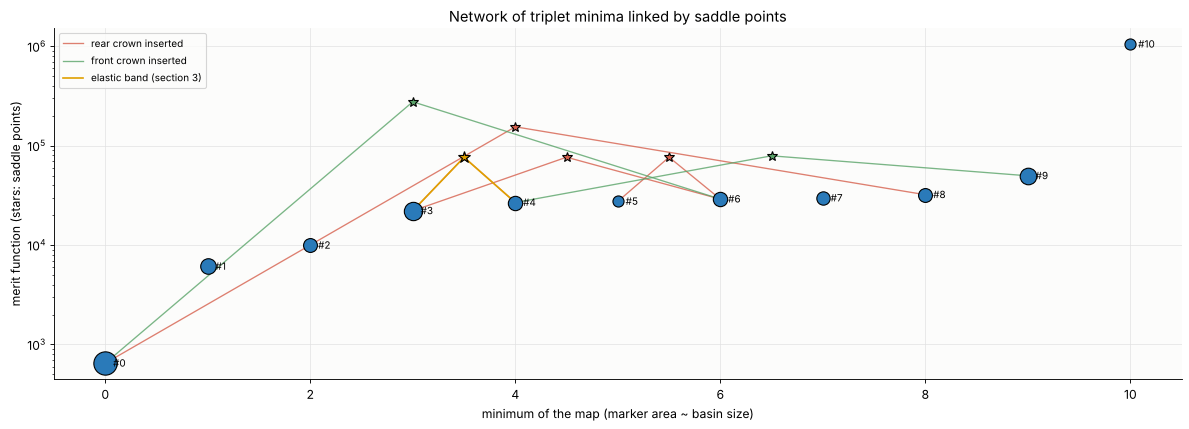

In [12]:
# the network: triplet minima of the map, linked by the constructed saddle points
fig, ax = plt.subplots(figsize=(15, 5.5))
nodes = {f"#{k}": (k, m.merit) for k, m in enumerate(minima)}
for k, m in enumerate(minima):
    ax.semilogy(k, m.merit, "o", ms=8 + 2*np.sqrt(m.count), color=BLUE, mec="k", zorder=3)
    ax.annotate(f"#{k}", (k, m.merit), xytext=(7, -3), textcoords="offset points", fontsize=9)
for cons_list, color, label in [(constructions, RED, "rear crown inserted"),
                                (fconstructions, GREEN, "front crown inserted")]:
    first = True
    for cons in cons_list:
        for e in cons:
            a, b = [end["name"] for end in e["ends"]]
            if a in nodes and b in nodes and a != b:
                (xa, ya), (xb, yb) = nodes[a], nodes[b]
                xm = (xa + xb)/2
                ym = max(e["saddle_merit"], ya, yb)
                ax.plot([xa, xm, xb], [ya, ym, yb], "-", color=color, lw=1.2, alpha=0.8,
                        label=label if first else None)
                ax.plot(xm, ym, "*", color=color, ms=9, mec="k")
                first = False
xm = (A + B)/2
ax.plot([A, xm, B], [minima[A].merit, ll.merit_at(opt, x_s), minima[B].merit], "-", color=ORANGE,
        lw=1.5, label="elastic band (section 3)")
ax.plot(xm, ll.merit_at(opt, x_s), "*", color=ORANGE, ms=11, mec="k")
ax.set_xlabel("minimum of the map (marker area ~ basin size)")
ax.set_ylabel("merit function (stars: saddle points)")
ax.set_title("Network of triplet minima linked by saddle points")
ax.legend(fontsize=9, loc="upper left")
fig.tight_layout()

In the picture, each line from a star (a saddle point, at its merit
function; saddle points of the constructions with a null lens of zero
thickness, which is not quite the triplet with a 4 mm lens, are drawn at
least as high as their minima) goes down to the two minima it links.
Bociort's group proposes to use the construction in practice: start from
a simple system, insert a lens where it gains most (compare the gain
estimate `DampedLeastSquares.predicted_gain()` of notebook 58
(lens optimization) for new variables), and keep the good branches, instead of
waiting for a random start to land in a good basin.

## 5. Global search at equal cost

How does one find the global minimum without a map? Three classical
strategies, compared by the number of merit function evaluations it
takes to reach the Cooke minimum #0 (a damped least squares run costs a
Jacobian, six evaluations, per iteration plus the trial steps; one run
from a random start costs about 300 evaluations here):

- **random starts** (multistart): independent local optimizations; the
  probability to have found #0 after $n$ runs is $1 - (1 - p)^n$ with $p$
  the share of its basin, estimated from the 200 runs of section 2 by
  shuffling their order;
- **basin hopping** (Wales and Doye, 1997): a random walk from minimum to
  minimum, with a random jump of the curvatures, a local optimization, and
  the Metropolis rule on the logarithm of the merit function to accept the
  new minimum (T = 1: a minimum *e* times worse is accepted with
  probability 1/e);
- **simulated annealing** without a local optimizer (scipy's
  `dual_annealing`, generalized simulated annealing of Tsallis and Stariolo,
  with the local search switched off), the method of the early global lens
  optimization papers.

In [13]:
target = minima[0].merit*1.001
rng = np.random.default_rng(7)
evals = np.array([r.evaluations for r in runs])
hit = np.array([r.merit <= target for r in runs])
budget = np.linspace(0, 12000, 121)


def first_hit(order):
    cum = np.cumsum(evals[order])
    k = np.flatnonzero(hit[order])
    return cum[k[0]] if len(k) else np.inf


ms_hits = np.array([first_hit(rng.permutation(len(runs))) for _ in range(2000)])
ms_curve = [np.mean(ms_hits <= b) for b in budget]

t0 = time.time()


def walks(n, step, hops=20):
    out = []
    for seed in range(n):
        x0 = ll.random_starts(opt, 1, rng=100 + seed)[0]
        out.append(ll.basin_hopping(opt, x0, hops=hops, step=step, temperature=1.0, rng=seed,
                                    max_iterations=150))
    return out


def first_hits(walk_list):
    hits = []
    for res in walk_list:
        k = np.flatnonzero(np.array([r.merit for r in res.runs]) <= target)
        hits.append(res.evaluations[k[0]] if len(k) else np.inf)
    return np.array(hits)


bh = walks(8, 4.0)        # jumps of 4 scaled units: 0.07/mm in each curvature
bh_small = walks(4, 1.0)  # small jumps
bh_hits, bh_small_hits = first_hits(bh), first_hits(bh_small)
print(f"basin hopping: {time.time() - t0:.0f} s")
for label, w, h in [("jumps of 4", bh, bh_hits), ("jumps of 1", bh_small, bh_small_hits)]:
    print(f"{label}: {np.sum(np.isfinite(h))} of {len(w)} walks reach #0, at "
          + ", ".join(f"{v:.0f}" for v in np.sort(h[np.isfinite(h)]))
          + " evaluations; accepted hops per walk: "
          + ", ".join(str(int(r.accepted[1:].sum())) for r in w)
          + "; minima visited per walk: "
          + ", ".join(str(len(ll.cluster_minima(r.runs, opt))) for r in w))
print(f"random starts: median cost {np.median(ms_hits):.0f} evaluations "
      f"(basin share p = {hit.mean():.2f})")

basin hopping: 244 s
jumps of 4: 7 of 8 walks reach #0, at 65, 79, 79, 1773, 2293, 2848, 4204 evaluations; accepted hops per walk: 14, 8, 14, 14, 11, 14, 7, 7; minima visited per walk: 7, 7, 7, 7, 7, 7, 9, 7
jumps of 1: 1 of 4 walks reach #0, at 65 evaluations; accepted hops per walk: 20, 20, 20, 20; minima visited per walk: 1, 1, 1, 2
random starts: median cost 1019 evaluations (basin share p = 0.21)


In [14]:
lo_b, hi_b = np.full(5, -CMAX), np.full(5, CMAX)


def penalized(x):
    m = ll.merit_at(opt, x)
    return m if np.isfinite(m) else 1e9


t0 = time.time()
sa = []
for seed in range(3):
    count = [0, np.inf, []]

    def f(x):
        m = penalized(x)
        count[0] += 1
        count[1] = min(count[1], m)
        count[2].append(count[1])
        return m

    res = dual_annealing(f, list(zip(lo_b, hi_b)), maxfun=6000, no_local_search=True, seed=seed)
    sa.append(np.array(count[2]))
print(f"simulated annealing: {time.time() - t0:.0f} s, best merit after 6000 evaluations: "
      + ", ".join(f"{s[-1]:.0f}" for s in sa))

simulated annealing: 81 s, best merit after 6000 evaluations: 24485, 6479, 43944


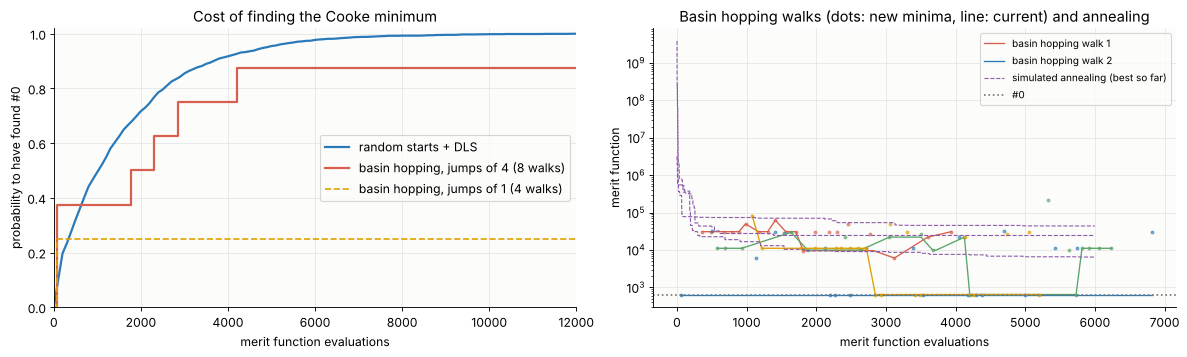

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
ax = axes[0]
ax.plot(budget, ms_curve, color=BLUE, lw=2, label="random starts + DLS")
found = np.sort(bh_hits[np.isfinite(bh_hits)])
ax.step(np.concatenate([[0], found, [budget[-1]]]),
        np.concatenate([np.arange(len(found) + 1), [len(found)]])/len(bh_hits), where="post",
        color=RED, lw=2, label=f"basin hopping, jumps of 4 ({len(bh)} walks)")
found = np.sort(bh_small_hits[np.isfinite(bh_small_hits)])
ax.step(np.concatenate([[0], found, [budget[-1]]]),
        np.concatenate([np.arange(len(found) + 1), [len(found)]])/len(bh_small_hits),
        where="post", color=ORANGE, lw=1.5, ls="--",
        label=f"basin hopping, jumps of 1 ({len(bh_small)} walks)")
ax.set_xlabel("merit function evaluations")
ax.set_ylabel("probability to have found #0")
ax.set_xlim(0, budget[-1])
ax.set_ylim(0, 1.02)
ax.legend()
ax.set_title("Cost of finding the Cooke minimum")
ax = axes[1]
for k, res in enumerate(bh[:4]):
    ax.semilogy(res.evaluations, [r.merit for r in res.runs], ".", color=[RED, BLUE, GREEN, ORANGE][k],
                ms=5, alpha=0.6)
    ax.semilogy(res.evaluations, res.current, "-", color=[RED, BLUE, GREEN, ORANGE][k], lw=1.2,
                label=f"basin hopping walk {k + 1}" if k < 2 else None)
for k, s in enumerate(sa):
    ax.semilogy(np.arange(1, len(s) + 1), s, color=PURPLE, lw=1, ls="--",
                label="simulated annealing (best so far)" if k == 0 else None)
ax.axhline(minima[0].merit, color=GREY, ls=":", label="#0")
ax.set_xlabel("merit function evaluations")
ax.set_ylabel("merit function")
ax.set_title("Basin hopping walks (dots: new minima, line: current) and annealing")
ax.legend(fontsize=9)
fig.tight_layout()

For this small problem random starts are hard to beat: one start in five
ends in the Cooke basin, and the median cost of finding it is about 1000
evaluations, three or four DLS runs. Basin hopping with large jumps (4
scaled units, 0.07 mm⁻¹ in each curvature, a third of the box) found #0 in
7 of 8 walks, but in the median after about 2000 evaluations, and one walk
that had found it later accepted a step uphill and left it again (the
best minimum is kept, of course). With jumps that large, a hop is little
more than a random restart. With small jumps (1 unit) the walks accept
every hop and still never leave the minimum they started in: the basins of
the triplet are wider than the jumps. Basin hopping pays off where good
minima lie close together (a funnel, as for the atomic clusters it was
invented for) and random starts rarely land in a good basin, as in larger
lens systems.

Simulated annealing without a local optimizer is far behind: after 6000
evaluations, the cost of 18 DLS runs (which find #0 with probability
0.99), its three runs are at 6479, 24485 and 43944, ten to seventy times
the merit function of #0. With Hessian eigenvalues spread over three
orders of magnitude and more, a random walk wastes almost every step on
the steep directions. This is why the practical global optimizers of lens
design (CODE V's Global Synthesis, the global search and Hammer
optimization of Zemax OpticStudio, the saddle-point construction) all
wrap a damped least squares core.

## 6. Summary

- The merit function of a lens has many local minima; a damped least
  squares run finds the one whose basin it starts in. For a Cooke
  triplet with fixed glasses and spacings, 200 random starts found 11
  interior minima; the classic Cooke form is the best and has the largest
  basin.
- Neighbouring minima are linked by saddle points of Morse index 1, which a
  nudged elastic band and eigenvector following find; the Hessian there
  has exactly one negative eigenvalue. The saddle point between two
  triplets can be a doublet with a nearly null lens.
- The saddle-point construction turns a minimum with N lenses into a
  saddle point with N + 1 lenses: a null lens of zero thickness, at a
  curvature where the derivative along its power vanishes. Descending on
  both sides and thickening the new lens gives two (N + 1)-lens minima;
  from doublets it reaches the Cooke triplet, both with a rear crown
  inserted behind the stop and with a front crown inserted before the
  flint.
- With a basin share of 21 %, random starts plus DLS find the global
  minimum fastest; basin hopping needs jumps as large as the basins and
  helps where good basins are small and close together; simulated
  annealing without a local optimizer is not competitive.

Related: notebooks [58 (lens optimization)](58_lens_optimization.ipynb) (damped
least squares, the triplet), [43 (Delano diagrams)](43_litho_delano_lens_design.ipynb)
(first order layout, which picks the basin before any optimization) and
[153 (multi-configuration optimization)](153_multiconfig_optimization.ipynb).

## References

- F. Bociort, E. van Driel and A. Serebriakov, "Networks of local minima in optical system optimization", Opt. Lett. 29, 189-191 (2004).
- F. Bociort, A. Serebriakov and M. van Turnhout, "Saddle points in the merit function landscape of systems of thin lenses in contact", Proc. SPIE 5523, 174-184 (2004).
- F. Bociort and M. van Turnhout, "Finding new local minima in lens design landscapes by constructing saddle points", Opt. Eng. 48, 063001 (2009).
- M. van Turnhout and F. Bociort, "Instabilities and fractal basins of attraction in optical system optimization", Opt. Express 17, 314-328 (2009).
- P. van Grol, F. Bociort and M. van Turnhout, "Finding order in the design landscape of simple optical systems", Proc. SPIE 7428 (2009).
- G. Henkelman, B. P. Uberuaga and H. Jónsson, "A climbing image nudged elastic band method for finding saddle points and minimum energy paths", J. Chem. Phys. 113, 9901-9904 (2000).
- D. J. Wales and J. P. K. Doye, "Global optimization by basin-hopping and the lowest energy structures of Lennard-Jones clusters containing up to 110 atoms", J. Phys. Chem. A 101, 5111-5116 (1997).
- C. Tsallis and D. A. Stariolo, "Generalized simulated annealing", Physica A 233, 395-406 (1996); Y. Xiang, D. Y. Sun, W. Fan and X. G. Gong, "Generalized simulated annealing algorithm and its application to the Thomson model", Phys. Lett. A 233, 216-220 (1997).
- G. W. Forbes and A. E. W. Jones, "Towards global optimization with adaptive simulated annealing", Proc. SPIE 1354, 144-153 (1991).
- M. Isshiki, H. Ono, K. Hiraga, J. Ishikawa and S. Nakadate, "Lens design: global optimization with escape function", Opt. Rev. 2, 463-470 (1995).
- H. D. Taylor, "Lens", British patent 22,607 (1893) (the Cooke triplet).

In [16]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 830 s
